In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('data_monitoring_server.csv')
df.head(10)

,log_id,tanggal,server_id,region,tipe_server,cpu_usage,memory_usage,disk_io_mbps,latency_ms,request_count,error_count,uptime_persen,insiden
0,LOG-0038,2024-01-29,SRV-13,Singapura,Compute,76.8,74.7,84.9,126.1,1969.0,2.0,99.79,Ya
1,LOG-0171,2024-03-07,SRV-02,Jakarta,Database,59.0,66.7,227.7,85.9,1483.0,1.0,99.76,Tidak
2,LOG-0257,2024-03-07,SRV-11,Singapura,Web,39.0,57.7,110.7,260.8,1514.0,0.0,99.95,Ya
3,LOG-0061,2024-03-17,SRV-14,Singapura,Web,NaN,50.5,5.0,60.5,738.0,1.0,99.58,Tidak
4,LOG-0154,2024-01-03,SRV-05,Jakarta,Database,58.9,66.6,169.2,65.5,1725.0,3.0,99.74,Tidak
5,LOG-0182,2024-03-15,SRV-03,Jakarta,Compute,56.5,65.5,84.1,81.4,1022.0,0.0,99.27,Tidak
6,LOG-0031,2024-02-19,SRV-07,Surabaya,Database,66.9,70.2,268.0,78.1,2099.0,1.0,99.48,Tidak
7,LOG-0100,2024-01-28,SRV-03,Jakarta,Compute,74.3,73.6,80.9,93.9,2396.0,1.0,99.93,Tidak
8,LOG-0142,2024-01-28,SRV-04,Jakarta,Web,46.7,61.1,125.6,61.6,816.0,1.0,99.93,Tidak
9,LOG-0127,2024-03-18,SRV-02,Jakarta,Database,51.6,63.3,161.4,81.0,2155.0,2.0,99.90,Tidak


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   log_id         308 non-null    object 
 1   tanggal        308 non-null    object 
 2   server_id      308 non-null    object 
 3   region         302 non-null    object 
 4   tipe_server    308 non-null    object 
 5   cpu_usage      295 non-null    float64
 6   memory_usage   293 non-null    float64
 7   disk_io_mbps   299 non-null    float64
 8   latency_ms     298 non-null    float64
 9   request_count  308 non-null    float64
 10  error_count    300 non-null    float64
 11  uptime_persen  308 non-null    float64
 12  insiden        308 non-null    object 
dtypes: float64(7), object(6)
memory usage: 31.4+ KB


In [3]:
df["region"]=df["region"].astype("category")
df["tipe_server"]=df["tipe_server"].astype("category")
df["insiden"]=df["insiden"].astype("category")
df["tanggal"]=df["tanggal"].astype("datetime64[ns]")

In [4]:
print(df["region"].value_counts())

region
Surabaya     110
Singapura    101
Jakarta       91
Name: count, dtype: int64


In [5]:
print(df["tipe_server"].value_counts())

tipe_server
Database    147
Web          95
Compute      66
Name: count, dtype: int64


In [6]:
print(df["insiden"].value_counts())

insiden
Tidak    254
Ya        54
Name: count, dtype: int64


In [7]:
duplicate=df.duplicated().sum()
print("jumlah data duplikat : ", duplicate)

jumlah data duplikat :  8


In [8]:
df=df.drop_duplicates()
print(df.duplicated().sum())

0


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [10]:
df.columns

Index(['log_id', 'tanggal', 'server_id', 'region', 'tipe_server', 'cpu_usage',
       'memory_usage', 'disk_io_mbps', 'latency_ms', 'request_count',
       'error_count', 'uptime_persen', 'insiden'],
      dtype='object')

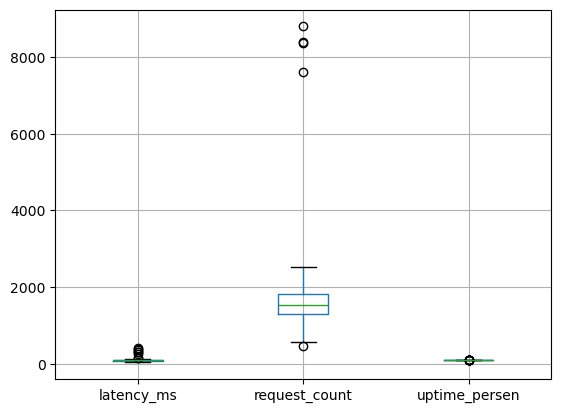

In [ ]:
boxes=df.boxplot(
    column=['latency_ms', 
            'request_count', 
            'uptime_persen'], 
            return_type='dict')

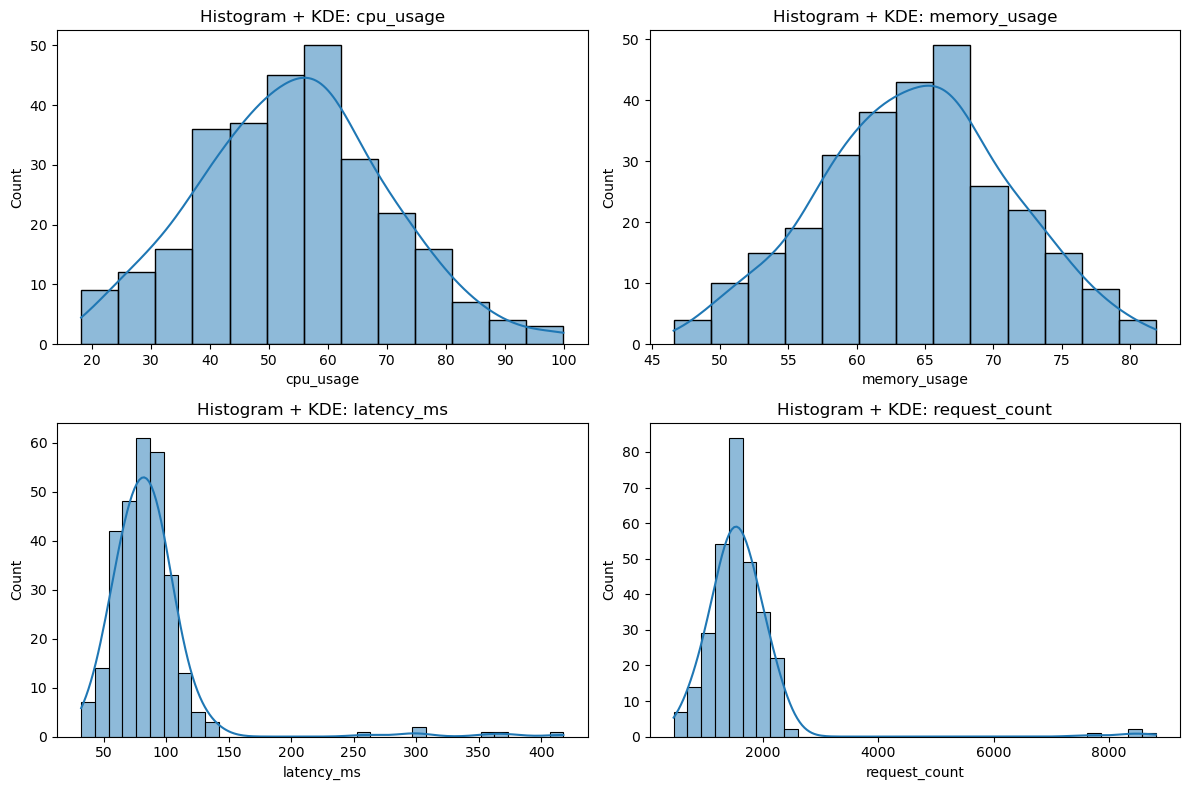

In [ ]:
import seaborn as sns

columns=['cpu_usage',
         'memory_usage',
         'latency_ms',
         'request_count',
         'uptime_persen']

fig,axes =plt.subplots(nrows=2, ncols=2, figsize=(12,8))
for column, ax in zip(columns, axes.flat):
    sns.histplot(data=df, x=column, kde=True, ax=ax)
    ax.set_title(f'Histogram + KDE: {column}')
    ax.set_xlabel(column)
    
plt.tight_layout()
plt.show()

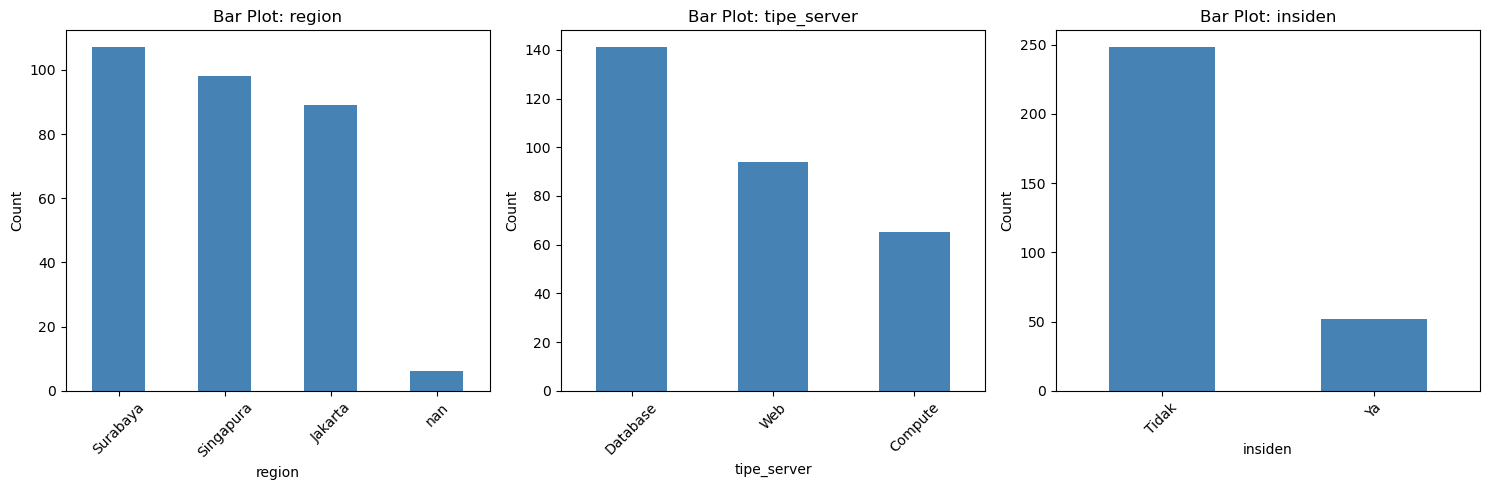

In [13]:
categorical_columns=['region','tipe_server','insiden']

fig, axes =plt.subplots(1,3, figsize=(15,5))
for column, ax in zip(categorical_columns, axes):
    df[column].value_counts(dropna=False).plot(
        kind='bar',
        ax=ax,
        color="steelblue"
        )
    ax.set_title(f'Bar Plot: {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=45)
    
plt.tight_layout()
plt.show()

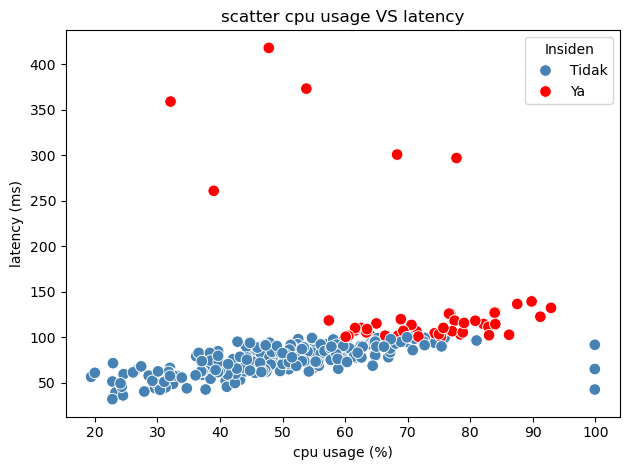

In [14]:
sns.scatterplot(
    data=df,
    x="cpu_usage",
    y="latency_ms",
    hue="insiden",
    palette={
        "Ya":"red", 
        "Tidak":"steelblue"},
    s=70
)

plt.title("scatter cpu usage VS latency")
plt.xlabel("cpu usage (%)")
plt.ylabel("latency (ms)")
plt.legend(title="Insiden")
plt.tight_layout()
plt.show()

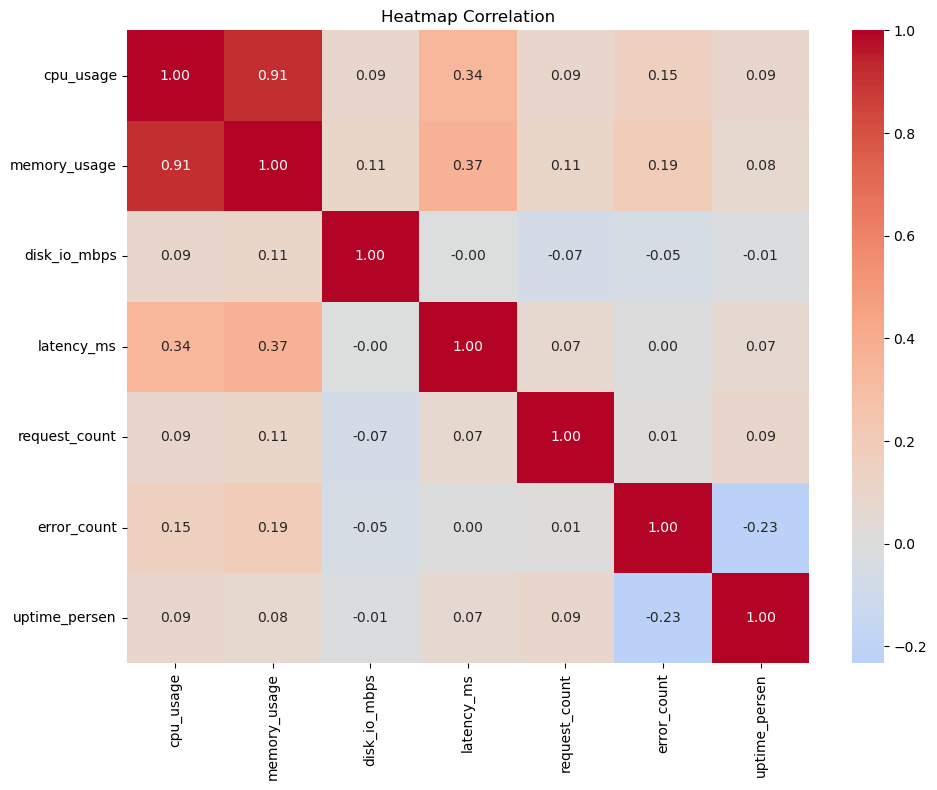

In [15]:
corr=df.select_dtypes(include="number").corr()
labels=corr.columns.tolist()

fig, ax=plt.subplots(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax, center=0)
ax.set_title("Heatmap Correlation")
plt.tight_layout()
plt.show()

In [16]:
tips = sns.load_dataset("tips")
tips.head()


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


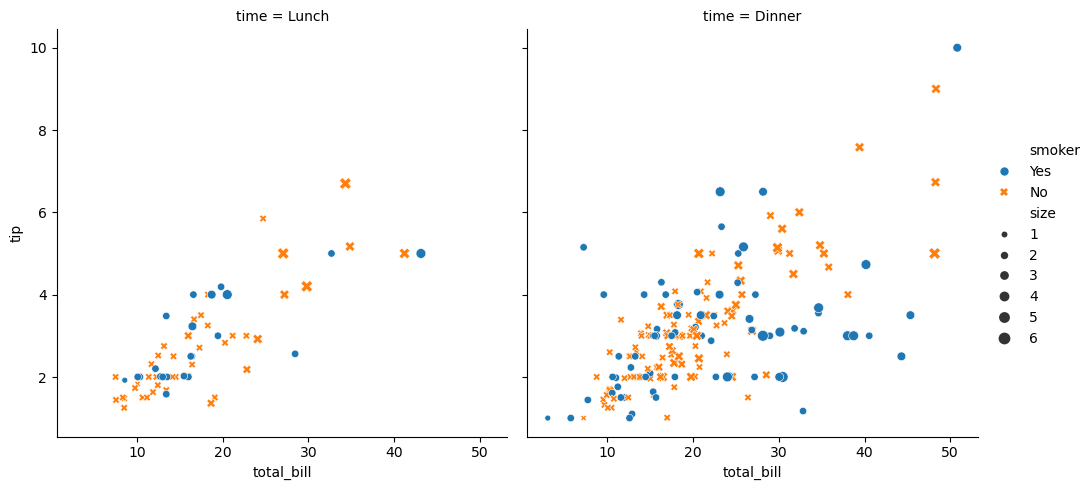

In [17]:
sns.relplot(
    data=tips,
    x="total_bill", y="tip", col="time",
    hue="smoker", style="smoker", size="size",
)

plt.show()

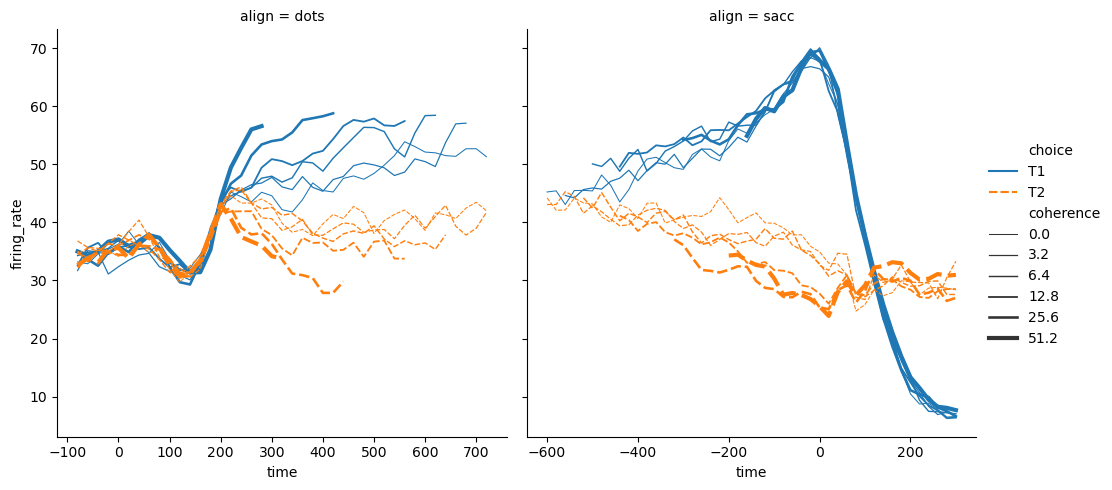

In [18]:
dots = sns.load_dataset("dots")
sns.relplot(
    data=dots, kind="line",
    x="time", y="firing_rate", col="align",
    hue="choice", size="coherence", style="choice",
    facet_kws=dict(sharex=False),
)

plt.show()